# Supplementary Figure 2 — Axis score slopes vs TMB (per cancer type)

Forest-style panels: OLS slope of TMB axis, PQC axis, and Non-PQC axis scores vs log TMB (+ purity), one panel per score.
Cancer types ordered like fig2a (TMB axis r, high → low).

Output: `results/figures/supplementary/supp_fig2/axis_score_slope.pdf`

In [35]:
import socket, os

hostname = socket.gethostname()
if "scg" in hostname:
    BASE_DIR = "/labs/mwinslow/Karen/protein-master/v2_pancan_batch_corrected"
else:
    BASE_DIR = os.path.expanduser("~/Documents/research/scg/protein-master/v2_pancan_batch_corrected")

WORKING_DIR=f"{BASE_DIR}/data/tcga_xena"
DATA_DIR = f"{BASE_DIR}/analysis/01_axis_analysis/bh/axis_sample_scores/tcga_xena"

os.chdir(WORKING_DIR)
print(f"📂 Working directory set to: {WORKING_DIR}")

📂 Working directory set to: /Users/karenshih/Documents/research/scg/protein-master/v2_pancan_batch_corrected/data/tcga_xena


In [36]:
import pandas as pd

In [37]:
pos_axis = pd.read_parquet(f"{DATA_DIR}/axis_sample_level.parquet")

In [38]:
##pos_axis[["barcode", "cancer_type", "purity"]].to_csv(f"{WORKING_DIR}/data_ready/barcode_purity.csv", index=False)

In [39]:
purity = pd.read_csv(f"{WORKING_DIR}/data_ready/barcode_purity.csv")

In [40]:
pos_axis["purity"] = purity["purity"]

In [ ]:
import statsmodels.api as sm

SCORES = ["TMB_axis_score", "pqc_axis_score", "non_pqc_axis_score"]
SCORE_LABELS = {
    "TMB_axis_score": "TMB axis",
    "pqc_axis_score": "PQC axis",
    "non_pqc_axis_score": "Non-PQC axis",
}

results = []

for score in SCORES:
    for cancer_type, df_ct in pos_axis.groupby("cancer_type"):
        X = sm.add_constant(df_ct[["log_mut", "purity"]])
        y = df_ct[score]

        model = sm.OLS(y, X).fit()

        results.append(
            {
                "cancer_type": cancer_type,
                "score": score,
                "score_label": SCORE_LABELS[score],
                "slope": model.params["log_mut"],
                "purity_coef": model.params["purity"],
                "intercept": model.params["const"],
                "slope_ci_low": model.conf_int().loc["log_mut", 0],
                "slope_ci_high": model.conf_int().loc["log_mut", 1],
                "r_squared": model.rsquared,
                "n": len(df_ct),
            }
        )

df_slopes = pd.DataFrame(results)

TABLE_DIR = f"{BASE_DIR}/results/tables/tableS2"
os.makedirs(TABLE_DIR, exist_ok=True)
df_slopes.to_csv(f"{TABLE_DIR}/axis_score_slope.csv", index=False)

df_slopes.head()

,cancer_type,score,score_label,slope,purity_coef,intercept,slope_ci_low,slope_ci_high,r_squared,n
0,ACC,TMB_axis_score,TMB axis,169.118836,-53.463354,-372.079162,101.786202,236.451471,0.247900,79
1,BLCA,TMB_axis_score,TMB axis,132.315237,-133.112244,-100.761811,97.846701,166.783773,0.176352,406
2,BRCA,TMB_axis_score,TMB axis,175.161980,-15.717800,-257.266405,150.793224,199.530735,0.166467,1018
3,CESC,TMB_axis_score,TMB axis,55.428742,5.790941,112.482683,29.828390,81.029094,0.060313,286
4,CHOL,TMB_axis_score,TMB axis,90.268864,-257.264220,-65.256458,-14.207216,194.744944,0.254623,36


In [42]:
import sys

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from matplotlib.gridspec import GridSpec

mpl.rcParams["pdf.fonttype"] = 42
mpl.rcParams["svg.fonttype"] = "none"

sys.path.insert(0, f"{BASE_DIR}/local/figures")
from palette import COLORS


def rasterize_figure(fig):
    """Rasterize line/marker artists in PDF; text stays vector."""
    from matplotlib.collections import LineCollection, PathCollection, PolyCollection
    from matplotlib.lines import Line2D

    for ax in fig.axes:
        for artist in ax.get_children():
            if isinstance(artist, (Line2D, PathCollection, LineCollection, PolyCollection)):
                artist.set_rasterized(True)

PALETTE = {
    "TMB_axis_score": "#0072B2",
    "pqc_axis_score": "#D55E00",
    "non_pqc_axis_score": "#009E73",
}

CI_COLOR = COLORS["light_gray"]
OUT_DIR = f"{BASE_DIR}/results/figures/supplementary/supp_fig2"
os.makedirs(OUT_DIR, exist_ok=True)

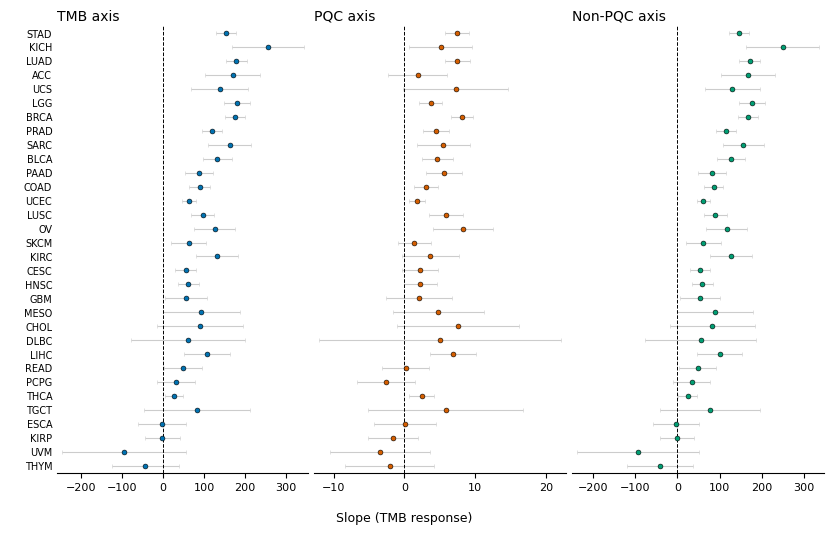

In [ ]:
CANCER_ORDER = (
    pd.read_csv(f"{BASE_DIR}/results/tables/score_corr_per_type_summary.csv")
    .loc[lambda d: d["score"] == "TMB_axis_score"]
    .sort_values("r", ascending=False)["cancer_type"]
    .tolist()
)

N_COLS = len(SCORES)
N_ROWS = 1
PANEL_SIZE = 3.2  # square data-panel side (inches)
LABEL_WIDTH = 0.85  # narrow column for cancer-type labels
FIG_WIDTH = LABEL_WIDTH + N_COLS * PANEL_SIZE
FIG_HEIGHT = N_ROWS * PANEL_SIZE


def _style_label_axis(ax_y, order, y):
    ax_y.set_yticks(y)
    ax_y.set_yticklabels(order, fontsize=7, ha="right")
    ax_y.set_ylim(-0.5, len(order) - 0.5)
    ax_y.invert_yaxis()
    ax_y.set_xticks([])
    ax_y.set_xlim(0, 1)
    ax_y.tick_params(axis="x", bottom=False)
    ax_y.tick_params(axis="y", length=0, pad=1, labelleft=False, labelright=True)
    ax_y.yaxis.set_ticks_position("right")
    for spine in ax_y.spines.values():
        spine.set_visible(False)


def plot_slope_by_score_panels(df, filename):
    """Forest-style panels: all cancer types together within each score."""
    order = CANCER_ORDER
    y = np.arange(len(order))

    fig = plt.figure(figsize=(FIG_WIDTH, FIG_HEIGHT))
    gs = GridSpec(
        N_ROWS,
        N_COLS + 1,
        figure=fig,
        width_ratios=[LABEL_WIDTH / PANEL_SIZE] + [1.0] * N_COLS,
        height_ratios=[1.0] * N_ROWS,
        wspace=0.04,
        hspace=0.06,
    )
    ax_y = fig.add_subplot(gs[0, 0])
    _style_label_axis(ax_y, order, y)

    for col, score in enumerate(SCORES, start=1):
        ax = fig.add_subplot(gs[0, col], sharey=ax_y)
        ax.set_box_aspect(1)
        df_sub = (
            df[df["score"] == score]
            .set_index("cancer_type")
            .reindex(order)
        )
        x_min = df_sub["slope_ci_low"].min()
        x_max = df_sub["slope_ci_high"].max()
        pad = 0.02 * (x_max - x_min)

        ax.errorbar(
            df_sub["slope"],
            y,
            xerr=[
                df_sub["slope"] - df_sub["slope_ci_low"],
                df_sub["slope_ci_high"] - df_sub["slope"],
            ],
            fmt="o",
            color=PALETTE[score],
            ecolor=CI_COLOR,
            elinewidth=0.8,
            capsize=1.5,
            markersize=3.5,
            markeredgecolor="black",
            markeredgewidth=0.4,
        )
        ax.axvline(0, color="black", linewidth=0.7, linestyle="--")
        ax.set_title(SCORE_LABELS[score], fontsize=9, loc="left", pad=2)
        ax.set_xlim(x_min - pad, x_max + pad)
        ax.tick_params(axis="y", left=False, labelleft=False)
        ax.tick_params(axis="x", labelsize=8)
        sns.despine(ax=ax, left=True, bottom=False)

    fig.supxlabel("Slope (TMB response)", fontsize=9, y=0.01)
    fig.subplots_adjust(left=0.06, right=0.99, top=0.97, bottom=0.05)
    rasterize_figure(fig)
    plt.savefig(f"{OUT_DIR}/{filename}.pdf", dpi=300, bbox_inches="tight", pad_inches=0.08)
    plt.show()


plot_slope_by_score_panels(df_slopes, "axis_score_slope")